# FYP-Pulse: Final Year Project Early Warning System
**Track 4 · Vibe Jam: AI Sprint · Department of Artificial Intelligence**

**Goal:** using only what is known at the end of **week 8**, estimate which FYP groups are likely to fail or carry over, so support can be offered early.

About 1 in 6 groups ends badly, so a model that says "No risk" for everyone looks 84% accurate and is useless. We therefore judge models on **recall, F1 and PR-AUC**, not accuracy.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
SEED = 42

raw = pd.read_csv("fyp_pulse_train.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (1840, 20)


,group_id,proposal_date,campus,program,leader_gender,group_size,team_avg_cgpa,team_min_cgpa,project_type,has_industry_sponsor,supervisor_experience_years,supervisor_active_groups,proposal_revisions,weeks_to_proposal_approval,supervisor_meetings_8wk,github_commits_8wk,mid_eval_score,final_defense_score,extension_granted,poor_outcome
0,G01536,17-Jun-25,Karachi,BSCS,Female,5.0,2.52,NaN,Mobile App,Yes,7.0,9.0,NaN,3.0,7.0,209.0,81.7,54.9,Yes,No
1,G00738,10/07/2024,Islamabad,BSCS,Female,4.0,3.39,2.72,IoT,No,10.0,6.0,1.0,1.0,7.0,106.0,78.9,74.9,No,No
2,G01295,2025-03-08,Lahore,BSCS,Male,4.0,3.03,2.68,IoT,No,11.0,6.0,1.0,12.0,5.0,46.0,63.2,83.6,No,No
3,G00326,23-Jan-24,Lahore,BSAI,Male,4.0,3.05,2.74,AI-ML,Yes,13.0,5.0,1.0,3.0,5.0,63.0,74.4,66.5,No,No
4,G00153,04-Nov-23,Lahore,BSAI,M,4.0,2.59,3.13,Mobile App,No,10.0,4.0,1.0,3.0,11.0,NaN,60.3,76.3,No,No


---
## A1 · Data Cleaning & Summary
### Step 0 · What is wrong with the raw data?

In [2]:
print("Exact duplicate rows :", raw.duplicated().sum())
print("Campus spellings     :", raw["campus"].nunique(), "different values for 8 campuses")
print("Gender labels        :", raw["leader_gender"].value_counts().to_dict())
print("Date formats (sample):", raw["proposal_date"].sample(6, random_state=1).tolist())
print()
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])

Exact duplicate rows : 40
Campus spellings     : 32 different values for 8 campuses
Gender labels        : {'Male': 991, 'Female': 751, 'M': 53, 'F': 45}
Date formats (sample): ['18-Jun-25', '21/11/2024', '2023-11-30', '2023-09-09', '03-May-25', '2025-05-26']

Missing values per column:
team_avg_cgpa                   60
team_min_cgpa                   48
project_type                    53
has_industry_sponsor            75
supervisor_experience_years    106
supervisor_active_groups        71
proposal_revisions              80
weeks_to_proposal_approval      88
supervisor_meetings_8wk         90
github_commits_8wk             110
mid_eval_score                  86
dtype: int64


In [3]:
# min / max per numeric column: look for impossible values
raw.describe().T[["min", "max"]]

,min,max
group_size,-3.0,15.0
team_avg_cgpa,-1.0,9.1
team_min_cgpa,-2.0,6.5
supervisor_experience_years,-4.0,120.0
supervisor_active_groups,1.0,14.0
proposal_revisions,0.0,7.0
weeks_to_proposal_approval,-5.0,90.0
supervisor_meetings_8wk,-6.0,200.0
github_commits_8wk,-50.0,99999.0
mid_eval_score,-20.0,250.0


### Step 1 · Valid ranges and labels from the problem statement

In [4]:
VALID_RANGES = {
    "group_size": (1, 5),
    "team_avg_cgpa": (0, 4),
    "team_min_cgpa": (0, 4),
    "supervisor_experience_years": (0, 45),
    "supervisor_active_groups": (1, 15),
    "proposal_revisions": (0, 10),
    "weeks_to_proposal_approval": (0, 30),
    "supervisor_meetings_8wk": (0, 30),
    "github_commits_8wk": (0, 1000),
    "mid_eval_score": (0, 100),
    "final_defense_score": (0, 100),
}
INTEGER_COLS = ["group_size", "supervisor_experience_years", "supervisor_active_groups", "proposal_revisions",
                "weeks_to_proposal_approval", "supervisor_meetings_8wk", "github_commits_8wk"]
CAMPUSES = ["Lahore", "Karachi", "Islamabad", "Faisalabad", "Multan", "Rawalpindi", "Peshawar", "Quetta"]
CAMPUS_ALIASES = {"lhr": "Lahore", "khi": "Karachi", "isb": "Islamabad", "fsd": "Faisalabad",
                  "rwp": "Rawalpindi", "pindi": "Rawalpindi", "pesh": "Peshawar"}

report = []                      # (rule broken, rows affected, how it was fixed)
corrected = {}                   # values corrected per column
def log(rule, n, fix, col=None):
    report.append((rule, int(n), fix))
    if col:
        corrected[col] = corrected.get(col, 0) + int(n)

### Step 2 · Standardise column names and remove duplicates

In [5]:
df = raw.copy()
df.columns = [re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_") for c in df.columns]
df = df.rename(columns={"extension_grant": "extension_granted"})
initial_rows = len(df)

n_exact = df.duplicated().sum()
df = df.drop_duplicates()
n_id = df["group_id"].duplicated().sum()
df = df.drop_duplicates(subset="group_id").reset_index(drop=True)
log("Duplicate rows", n_exact + n_id, f"Removed {n_exact} exact duplicates and {n_id} repeated group IDs.")
print(initial_rows, "->", len(df), "rows")

1840 -> 1800 rows


### Step 3 · Fix inconsistent spellings (campus, gender)

In [6]:
def fix_campus(v):
    k = str(v).strip().lower()
    if k in CAMPUS_ALIASES:
        return CAMPUS_ALIASES[k]
    return next((c for c in CAMPUSES if c.lower() == k), np.nan)

before = df["campus"].copy()
df["campus"] = df["campus"].map(fix_campus)
log("Inconsistent campus spelling", (before != df["campus"]).sum(),
    "Mapped case variants, trailing spaces and short forms (Lhr, KHI, ISB, Fsd, RWP, Pindi, Pesh) to the 8 official names.", "campus")

before = df["leader_gender"].copy()
df["leader_gender"] = df["leader_gender"].str.strip().str.upper().map({"M": "Male", "MALE": "Male", "F": "Female", "FEMALE": "Female"})
log("Gender coded as M / F", (before != df["leader_gender"]).sum(), "Converted M to Male and F to Female.", "leader_gender")

print("Campuses now:", df["campus"].value_counts().to_dict())
print("Gender now  :", df["leader_gender"].value_counts().to_dict())

Campuses now: {'Karachi': 348, 'Lahore': 341, 'Islamabad': 230, 'Faisalabad': 204, 'Multan': 185, 'Peshawar': 181, 'Rawalpindi': 173, 'Quetta': 138}
Gender now  : {'Male': 1019, 'Female': 781}


### Step 4 · Convert mixed date formats to YYYY-MM-DD

In [7]:
def parse_date(s):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d-%b-%y"):      # 2025-03-08, 10/07/2024, 17-Jun-25
        try:
            return pd.to_datetime(str(s).strip(), format=fmt)
        except ValueError:
            pass
    return pd.NaT

parsed = df["proposal_date"].map(parse_date)
was_iso = df["proposal_date"].str.match(r"^\d{4}-\d{2}-\d{2}$")
log("Mixed date formats", (~was_iso).sum(), "Converted DD/MM/YYYY and DD-Mon-YY to YYYY-MM-DD.", "proposal_date")
df["proposal_date"] = parsed.dt.strftime("%Y-%m-%d")
print("Unparseable dates:", parsed.isna().sum())
df["proposal_date"].head()

Unparseable dates: 0


0    2025-06-17
1    2024-07-10
2    2025-03-08
3    2024-01-23
4    2023-11-04
Name: proposal_date, dtype: str

### Step 5 · Impossible values (outside the valid range) are errors
They are set to missing here and filled in Step 6.

In [8]:
out_of_range = {}
for col, (lo, hi) in VALID_RANGES.items():
    bad = df[col].notna() & ((df[col] < lo) | (df[col] > hi))
    if bad.sum():
        examples = ", ".join(f"{v:g}" for v in sorted(df.loc[bad, col].unique())[:4])
        df.loc[bad, col] = np.nan
        out_of_range[col] = int(bad.sum())
        log(f"Out of range: {col}", bad.sum(), f"Values outside {lo}-{hi} (e.g. {examples}) set to missing, then filled.", col)
pd.Series(out_of_range, name="impossible values removed")

group_size                     6
team_avg_cgpa                  6
team_min_cgpa                  4
supervisor_experience_years    4
weeks_to_proposal_approval     4
supervisor_meetings_8wk        4
github_commits_8wk             5
mid_eval_score                 4
Name: impossible values removed, dtype: int64

### Step 6 · Fill missing values
- CGPA: filled from the team's *other* CGPA ± the median gap, so `min <= avg` stays true.
- Other numeric columns: median (robust to outliers).
- Categorical columns: most common value.

In [9]:
gap = (df["team_avg_cgpa"] - df["team_min_cgpa"]).clip(lower=0).median()
for col, other, sign in [("team_avg_cgpa", "team_min_cgpa", +1), ("team_min_cgpa", "team_avg_cgpa", -1)]:
    miss = df[col].isna()
    originally_missing = miss.sum() - out_of_range.get(col, 0)
    use_other = miss & df[other].notna()
    df.loc[use_other, col] = (df.loc[use_other, other] + sign * gap).clip(0, 4)
    df[col] = df[col].fillna(df[col].median())
    log(f"Missing: {col}", originally_missing, f"Filled from the team's other CGPA (+/- median gap {gap:.2f}).", col)

for col in df.columns:
    n = df[col].isna().sum()
    if n == 0:
        continue
    if col in VALID_RANGES:
        fill = df[col].median()
        fill = round(fill) if col in INTEGER_COLS else fill
    else:
        fill = df[col].mode()[0]
    df[col] = df[col].fillna(fill)
    originally_missing = n - out_of_range.get(col, 0)
    if originally_missing:
        log(f"Missing: {col}", originally_missing, f"Filled with {'median' if col in VALID_RANGES else 'most common value'} ({fill}).", col)

print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


### Step 7 · Logical CGPA rules

In [10]:
bad = df["team_min_cgpa"] > df["team_avg_cgpa"]
log("team_min_cgpa above team_avg_cgpa", bad.sum(), "Weakest member cannot be above the average: min capped at avg.", "team_min_cgpa")
df.loc[bad, "team_min_cgpa"] = df.loc[bad, "team_avg_cgpa"]

solo = (df["group_size"] == 1) & (df["team_min_cgpa"] != df["team_avg_cgpa"])
log("Solo group with min != avg", solo.sum(), "In a one-person group min must equal avg: min set to avg.", "team_min_cgpa")
df.loc[solo, "team_min_cgpa"] = df.loc[solo, "team_avg_cgpa"]

for col in INTEGER_COLS:
    df[col] = df[col].round().astype(int)
df["y"] = (df["poor_outcome"] == "Yes").astype(int)

### Report: how many rows broke each rule and how they were fixed

In [11]:
rules = pd.DataFrame(report, columns=["Rule broken", "Rows affected", "How it was fixed"])
rules

,Rule broken,Rows affected,How it was fixed
0,Duplicate rows,40,Removed 40 exact duplicates and 0 repeated group IDs.
1,Inconsistent campus spelling,250,"Mapped case variants, trailing spaces and short forms (Lhr, KHI, ISB, Fsd, RWP, Pindi, Pesh) to the 8 official names."
2,Gender coded as M / F,96,Converted M to Male and F to Female.
3,Mixed date formats,980,Converted DD/MM/YYYY and DD-Mon-YY to YYYY-MM-DD.
4,Out of range: group_size,6,"Values outside 1-5 (e.g. -3, 0, 9, 12) set to missing, then filled."
5,Out of range: team_avg_cgpa,6,"Values outside 0-4 (e.g. -1, -0.5, 4.6, 5.7) set to missing, then filled."
6,Out of range: team_min_cgpa,4,"Values outside 0-4 (e.g. -2, -1.5, 5, 6.5) set to missing, then filled."
7,Out of range: supervisor_experience_years,4,"Values outside 0-45 (e.g. -4, 70, 85, 120) set to missing, then filled."
8,Out of range: weeks_to_proposal_approval,4,"Values outside 0-30 (e.g. -5, -2, 60, 90) set to missing, then filled."
9,Out of range: supervisor_meetings_8wk,4,"Values outside 0-30 (e.g. -6, -1, 90, 200) set to missing, then filled."


In [12]:
pd.Series(corrected, name="Values corrected").sort_values(ascending=False).to_frame()

,Values corrected
proposal_date,980
campus,250
github_commits_8wk,112
supervisor_experience_years,108
leader_gender,96
supervisor_meetings_8wk,94
mid_eval_score,90
weeks_to_proposal_approval,88
proposal_revisions,80
has_industry_sponsor,73


### Data-quality summary

In [13]:
summary = pd.Series({
    "Initial rows": initial_rows,
    "Cleaned rows": len(df),
    "Values corrected": sum(corrected.values()),
    "Total poor outcomes": df["y"].sum(),
    "Poor-outcome rate": f"{df['y'].mean():.1%}",
}, name="Value")
summary.to_frame()

,Value
Initial rows,1840
Cleaned rows,1800
Values corrected,2230
Total poor outcomes,288
Poor-outcome rate,16.0%


In [14]:
# sanity checks: every rule now holds
for c, (lo, hi) in VALID_RANGES.items():
    assert df[c].between(lo, hi).all(), c
assert (df["team_min_cgpa"] <= df["team_avg_cgpa"]).all()
assert (df.loc[df.group_size == 1, "team_min_cgpa"] == df.loc[df.group_size == 1, "team_avg_cgpa"]).all()
assert df.isna().sum().sum() == 0 and not df["group_id"].duplicated().any()
df.drop(columns="y").to_csv("fyp_pulse_clean.csv", index=False)
print("All cleaning rules pass. Clean file saved: fyp_pulse_clean.csv")

All cleaning rules pass. Clean file saved: fyp_pulse_clean.csv


---
## A2 · Dashboards & Visualizations
### Engineered features
| Feature | What it measures | Why it should matter |
|---|---|---|
| **commits_per_member** | GitHub commits in 8 weeks / group size | Raw commits favour big teams; per-person activity shows real effort |
| **cgpa_gap** | team_avg_cgpa - team_min_cgpa | A big gap means one member is far behind, so work piles onto the others |
| **meetings_per_load** | supervisor meetings / supervisor's active groups | How much attention the group gets relative to how stretched the supervisor is |

In [15]:
def add_features(d):
    d = d.copy()
    d["cgpa_gap"] = (d["team_avg_cgpa"] - d["team_min_cgpa"]).clip(lower=0)
    d["commits_per_member"] = d["github_commits_8wk"] / d["group_size"].clip(lower=1)
    d["meetings_per_load"] = d["supervisor_meetings_8wk"] / d["supervisor_active_groups"].clip(lower=1)
    return d

df = add_features(df)
BASE = df["y"].mean()
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

def rate_plot(ax, col, bins, labels, title, xlabel):
    band = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    r = df.groupby(band, observed=True)["y"].agg(["mean", "size"])
    ax.bar(r.index.astype(str), r["mean"], color=["#d9534f" if v > BASE else "#5b8def" for v in r["mean"]])
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(i, m + 0.008, f"{m:.0%}\nn={n}", ha="center", fontsize=9)
    ax.axhline(BASE, ls="--", c="grey", label=f"Overall {BASE:.0%}")
    ax.set(title=title, xlabel=xlabel, ylabel="Poor-outcome rate", ylim=(0, r["mean"].max() * 1.3))
    ax.yaxis.set_major_formatter(pct); ax.legend()
    return r["mean"]

### Chart 1 · Team factor: weakest member's CGPA

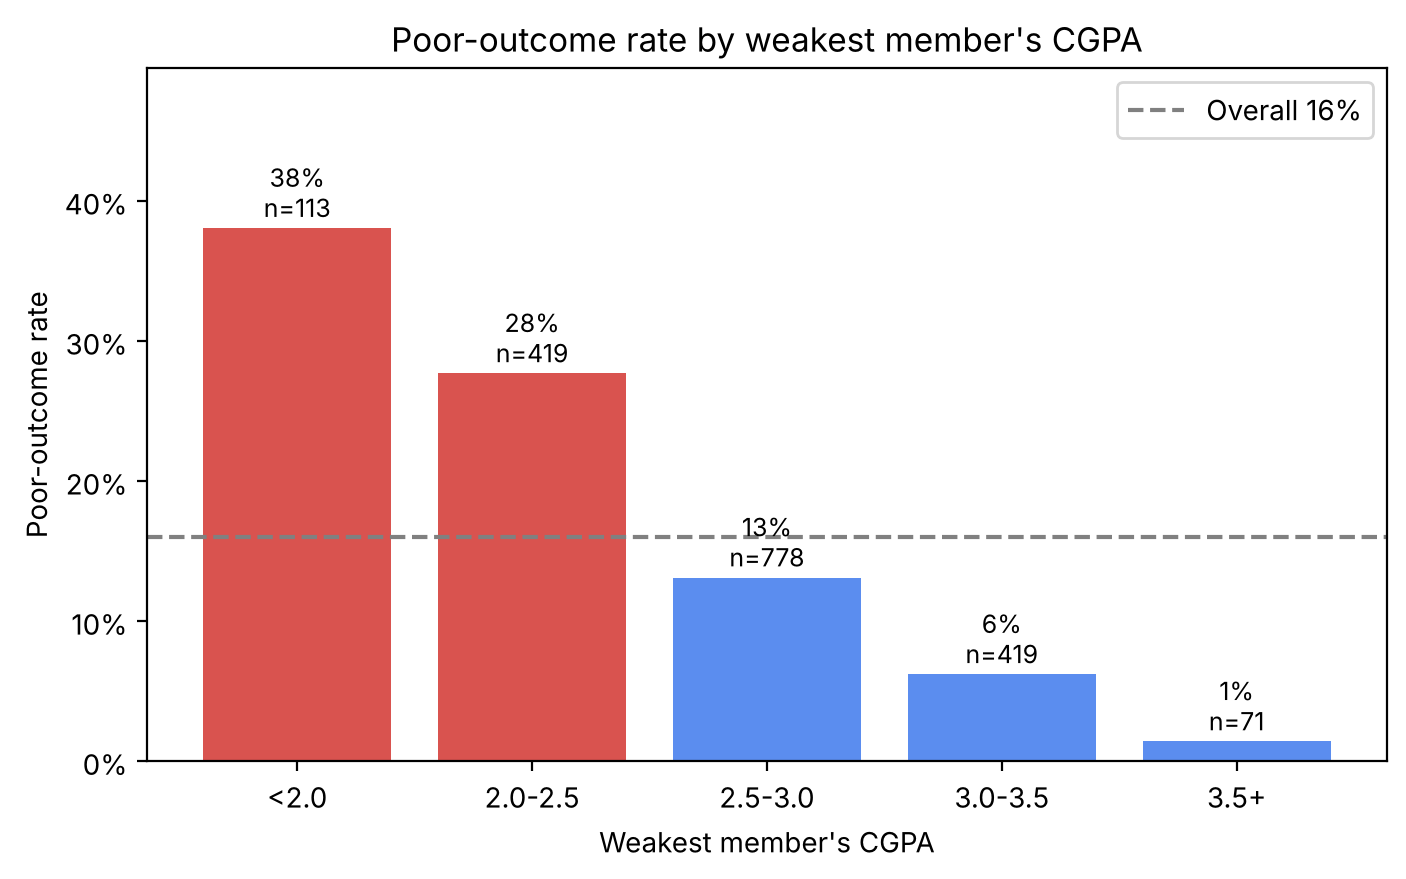

Insight: groups whose weakest student is below 2.0 CGPA end badly 38% of the time vs 1% at 3.5+. A team is only as strong as its weakest member.


In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
c1 = rate_plot(ax, "team_min_cgpa", [0, 2, 2.5, 3, 3.5, 4], ["<2.0", "2.0-2.5", "2.5-3.0", "3.0-3.5", "3.5+"],
               "Poor-outcome rate by weakest member's CGPA", "Weakest member's CGPA")
plt.show()
print(f"Insight: groups whose weakest student is below 2.0 CGPA end badly {c1.iloc[0]:.0%} of the time vs {c1.iloc[-1]:.0%} at 3.5+. A team is only as strong as its weakest member.")

### Chart 2 · Supervisor factor: meetings in the first 8 weeks

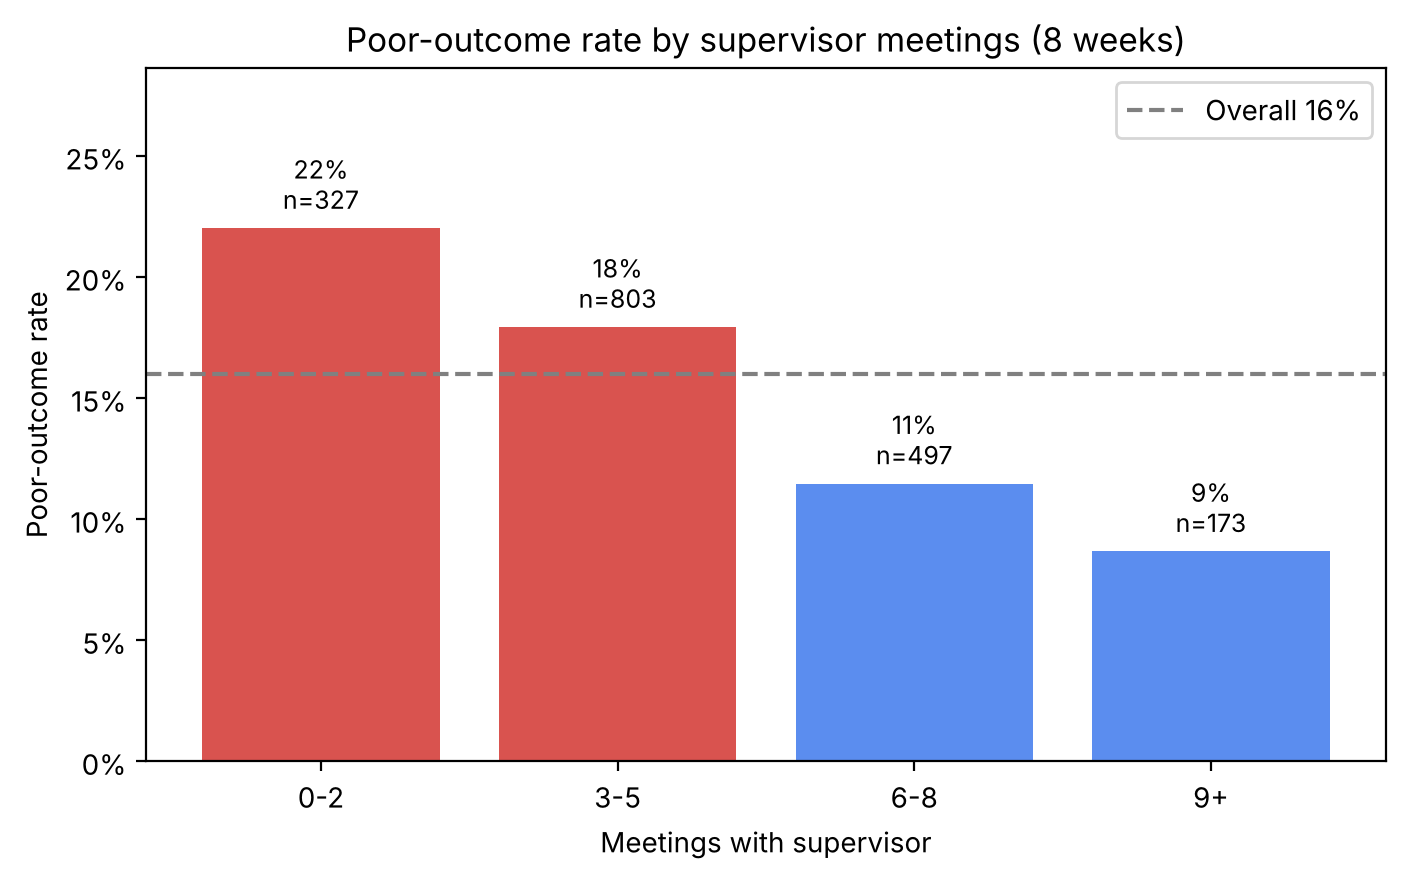

Insight: groups with 0-2 supervisor meetings fail 22% of the time; roughly weekly contact (9+) cuts that to 9%.


In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
c2 = rate_plot(ax, "supervisor_meetings_8wk", [0, 2, 5, 8, 30], ["0-2", "3-5", "6-8", "9+"],
               "Poor-outcome rate by supervisor meetings (8 weeks)", "Meetings with supervisor")
plt.show()
print(f"Insight: groups with 0-2 supervisor meetings fail {c2.iloc[0]:.0%} of the time; roughly weekly contact (9+) cuts that to {c2.iloc[-1]:.0%}.")

### Chart 3 · Project context: project type and industry sponsor

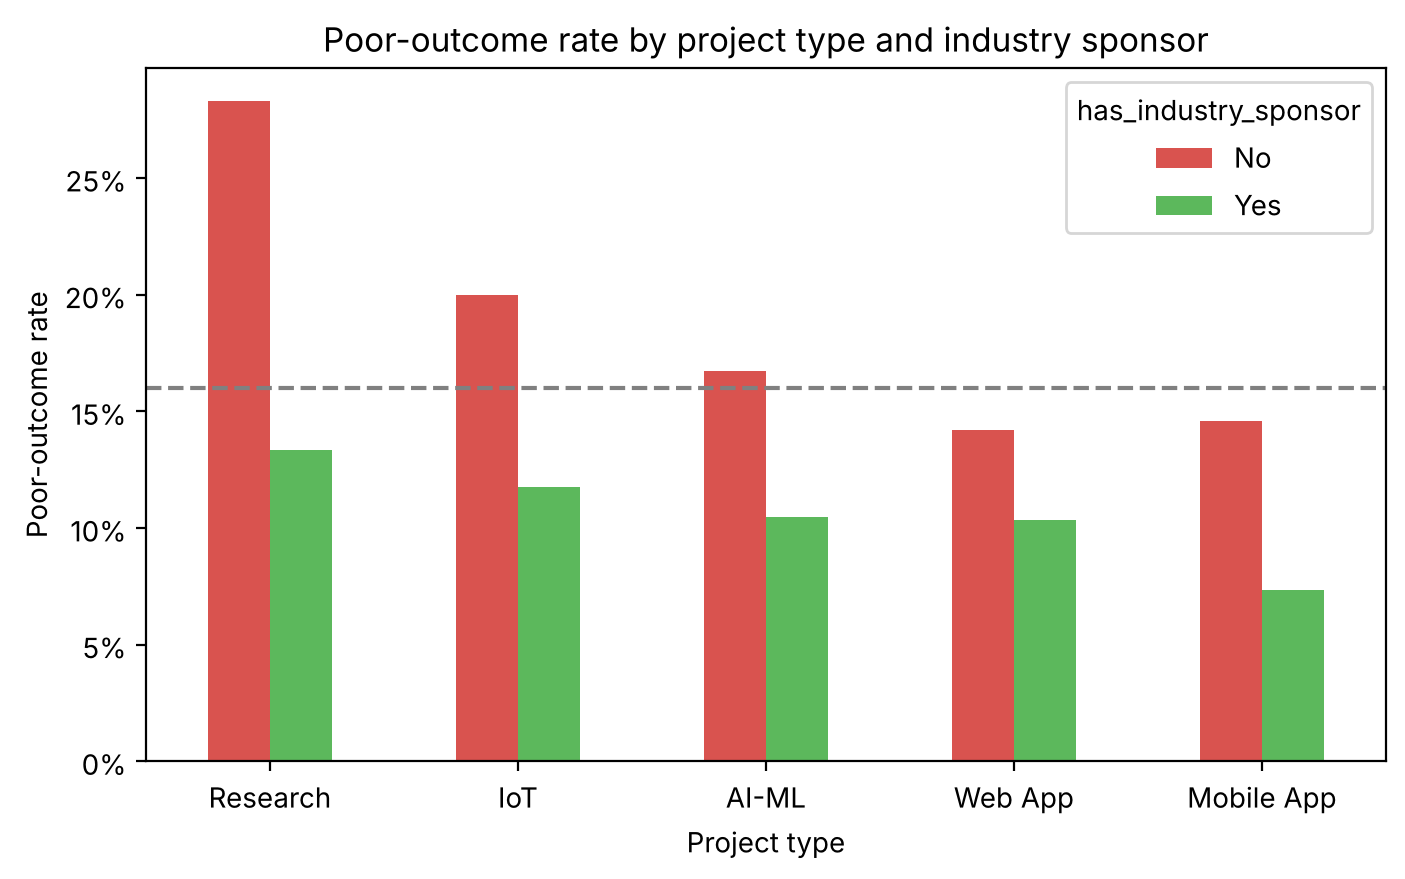

Insight: Research projects are the riskiest (26% vs 13% for Mobile App), and an industry sponsor lowers risk (10% vs 17%).


In [18]:
order = df.groupby("project_type")["y"].mean().sort_values(ascending=False).index
t = df.groupby(["project_type", "has_industry_sponsor"])["y"].mean().unstack().loc[order]
ax = t.plot.bar(figsize=(8, 4.5), color={"No": "#d9534f", "Yes": "#5cb85c"}, rot=0)
ax.axhline(BASE, ls="--", c="grey"); ax.yaxis.set_major_formatter(pct)
ax.set(title="Poor-outcome rate by project type and industry sponsor", xlabel="Project type", ylabel="Poor-outcome rate")
plt.show()
pt, sp = df.groupby("project_type")["y"].mean(), df.groupby("has_industry_sponsor")["y"].mean()
print(f"Insight: {pt.idxmax()} projects are the riskiest ({pt.max():.0%} vs {pt.min():.0%} for {pt.idxmin()}), and an industry sponsor lowers risk ({sp['Yes']:.0%} vs {sp['No']:.0%}).")

### Chart 4 · Engineered feature: commits per member

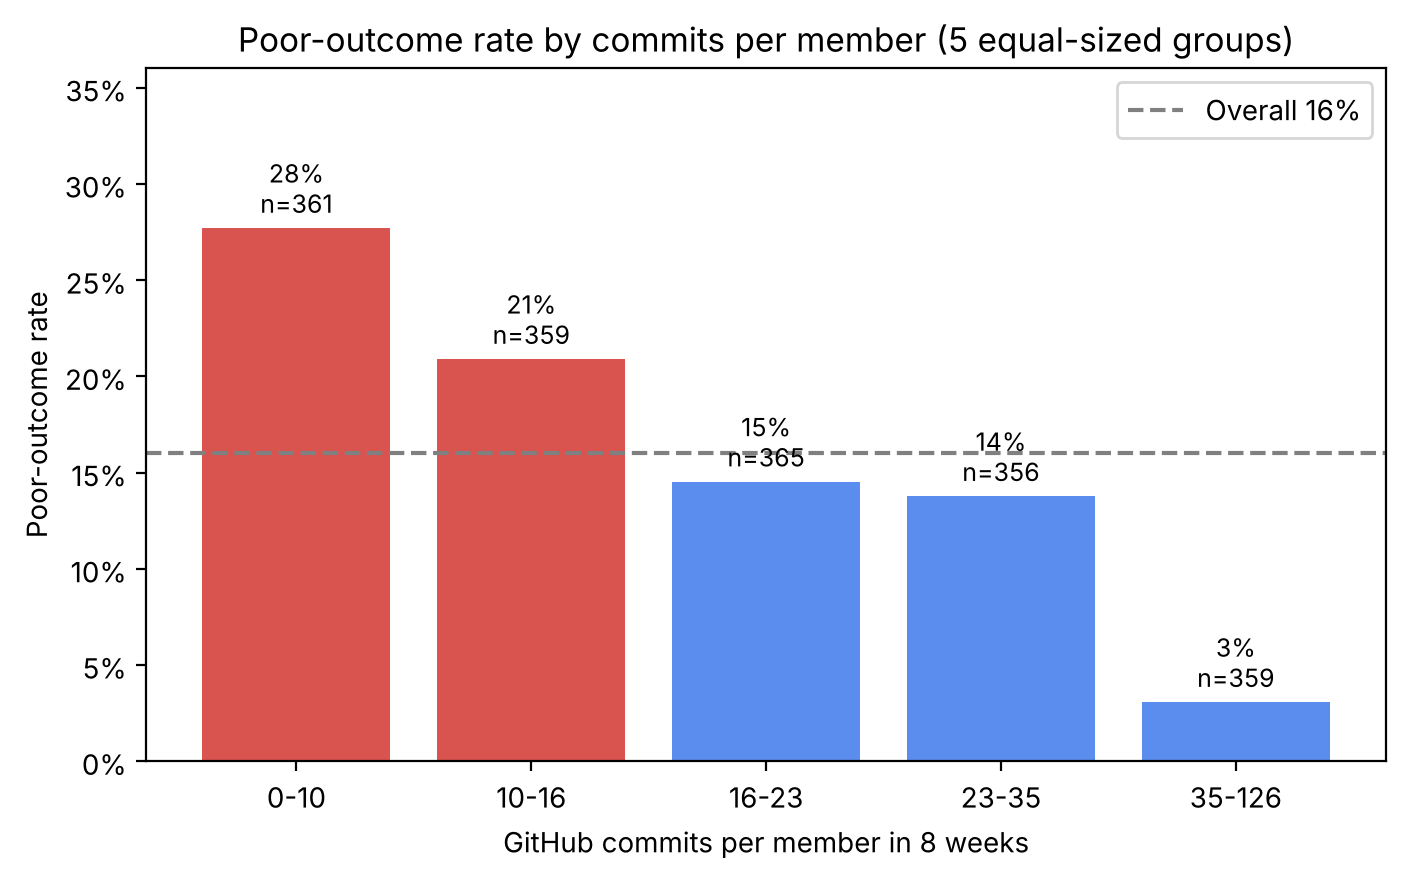

Insight: the least active fifth of groups fail 28% of the time vs 3% for the most active fifth. Per-person effort matters more than raw commits.


In [19]:
q = pd.qcut(df["commits_per_member"], 5)
edges = [q.cat.categories[0].left] + [iv.right for iv in q.cat.categories]
labels = [f"{iv.left:.0f}-{iv.right:.0f}" for iv in q.cat.categories]
fig, ax = plt.subplots(figsize=(8, 4.5))
c4 = rate_plot(ax, "commits_per_member", edges, labels,
               "Poor-outcome rate by commits per member (5 equal-sized groups)", "GitHub commits per member in 8 weeks")
plt.show()
print(f"Insight: the least active fifth of groups fail {c4.iloc[0]:.0%} of the time vs {c4.iloc[-1]:.0%} for the most active fifth. Per-person effort matters more than raw commits.")

### Extra · Mid-evaluation score

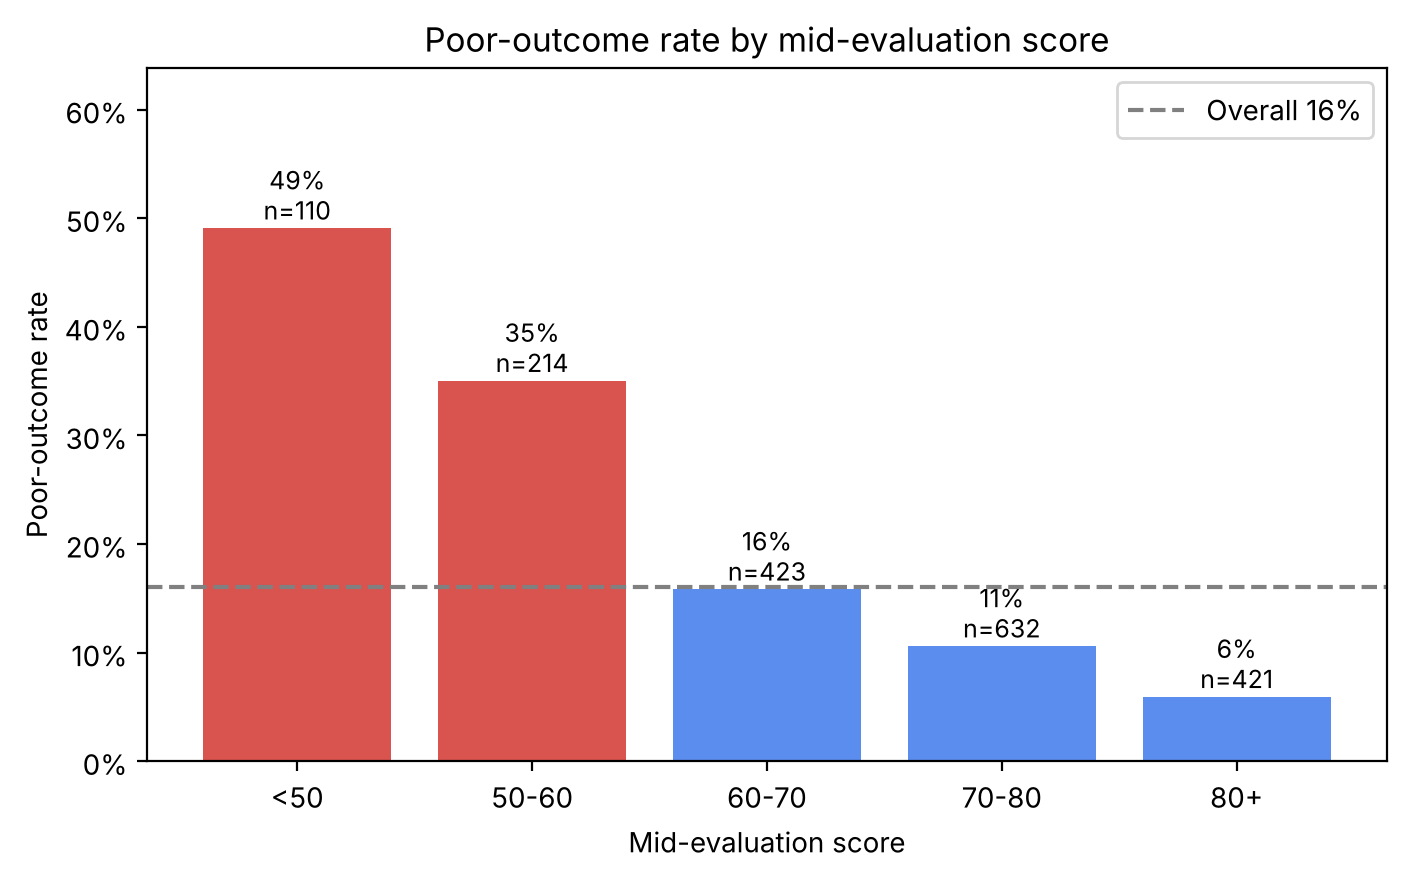

Insight: the strongest week-8 signal. Below 50 means 49% end badly; 80+ means only 6%.


In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
c5 = rate_plot(ax, "mid_eval_score", [0, 50, 60, 70, 80, 100], ["<50", "50-60", "60-70", "70-80", "80+"],
               "Poor-outcome rate by mid-evaluation score", "Mid-evaluation score")
plt.show()
print(f"Insight: the strongest week-8 signal. Below 50 means {c5.iloc[0]:.0%} end badly; 80+ means only {c5.iloc[-1]:.0%}.")

---
## A3 · Model Training & Selection
### Columns dropped and why

In [21]:
DROPPED = pd.DataFrame([
    ("final_defense_score", "Leakage", "Only known at the end of the project. It is basically the answer."),
    ("extension_granted", "Leakage", "Decided in the final phase, long after week 8."),
    ("group_id", "Identifier", "A random label with no meaning."),
    ("proposal_date", "Not predictive", "A calendar date ties the model to past intakes, not to the group's situation."),
    ("leader_gender", "Fairness", "Protected attribute. Kept out of the model, used only for the fairness check (A5)."),
    ("campus", "Fairness", "Not actionable and little signal after cleaning. Used only for the fairness check (A5)."),
    ("poor_outcome", "Target", "This is what we predict."),
], columns=["Column", "Reason", "Explanation"])
DROPPED

,Column,Reason,Explanation
0,final_defense_score,Leakage,Only known at the end of the project. It is basically the answer.
1,extension_granted,Leakage,"Decided in the final phase, long after week 8."
2,group_id,Identifier,A random label with no meaning.
3,proposal_date,Not predictive,"A calendar date ties the model to past intakes, not to the group's situation."
4,leader_gender,Fairness,"Protected attribute. Kept out of the model, used only for the fairness check (A5)."
5,campus,Fairness,Not actionable and little signal after cleaning. Used only for the fairness check (A5).
6,poor_outcome,Target,This is what we predict.


In [22]:
# proof that extension_granted leaks the answer
pd.crosstab(df["extension_granted"], df["poor_outcome"], normalize="index").round(2)

poor_outcome,No,Yes
extension_granted,,
No,0.97,0.03
Yes,0.26,0.74


In [23]:
NUM = ["group_size", "team_avg_cgpa", "team_min_cgpa", "supervisor_experience_years", "supervisor_active_groups",
       "proposal_revisions", "weeks_to_proposal_approval", "supervisor_meetings_8wk", "github_commits_8wk",
       "mid_eval_score", "cgpa_gap", "commits_per_member", "meetings_per_load"]
CAT = ["program", "project_type", "has_industry_sponsor"]
X, y = df[NUM + CAT], df["y"].values
print(len(NUM + CAT), "features:", NUM + CAT)

16 features: ['group_size', 'team_avg_cgpa', 'team_min_cgpa', 'supervisor_experience_years', 'supervisor_active_groups', 'proposal_revisions', 'weeks_to_proposal_approval', 'supervisor_meetings_8wk', 'github_commits_8wk', 'mid_eval_score', 'cgpa_gap', 'commits_per_member', 'meetings_per_load', 'program', 'project_type', 'has_industry_sponsor']


### Training setup
- **Stratified 80/20 split:** both sets keep the same ~16% poor-outcome share.
- **5-fold stratified cross-validation** on the training set to compare models and **pick each model's threshold** (max F1). The test set is never used for tuning.
- **Class imbalance:** balanced class weights in every model.
- Scaling and one-hot encoding happen inside a `Pipeline`, so nothing leaks across folds.

In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_train)} groups ({y_train.mean():.1%} poor) | Test: {len(X_test)} groups ({y_test.mean():.1%} poor)")

preprocess = ColumnTransformer([("num", StandardScaler(), NUM),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, C=0.5),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=250, max_leaf_nodes=15,
                                                        l2_regularization=1.0, class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def best_f1_threshold(y_true, p):
    grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    return float(grid[np.argmax([f1_score(y_true, p >= t) for t in grid])])

Train: 1440 groups (16.0% poor) | Test: 360 groups (16.1% poor)


In [25]:
rows, fitted, oof_probs, test_probs = [], {}, {}, {}
for name, clf in models.items():
    pipe = Pipeline([("pre", preprocess), ("clf", clf)])
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    t = best_f1_threshold(y_train, oof)                     # threshold from CV only
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= t).astype(int)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p), "Threshold": t,
                 "CV ROC-AUC": roc_auc_score(y_train, oof), "CV PR-AUC": average_precision_score(y_train, oof)})
    fitted[name], oof_probs[name], test_probs[name] = pipe, oof, p

results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Threshold,CV ROC-AUC,CV PR-AUC
Model,,,,,,,,,
Logistic Regression,0.822,0.458,0.569,0.508,0.799,0.417,0.68,0.829,0.455
Random Forest,0.764,0.369,0.655,0.472,0.794,0.407,0.37,0.804,0.432
Extra Trees,0.806,0.397,0.397,0.397,0.779,0.391,0.55,0.804,0.434
Gradient Boosting,0.689,0.312,0.776,0.446,0.781,0.432,0.17,0.791,0.401


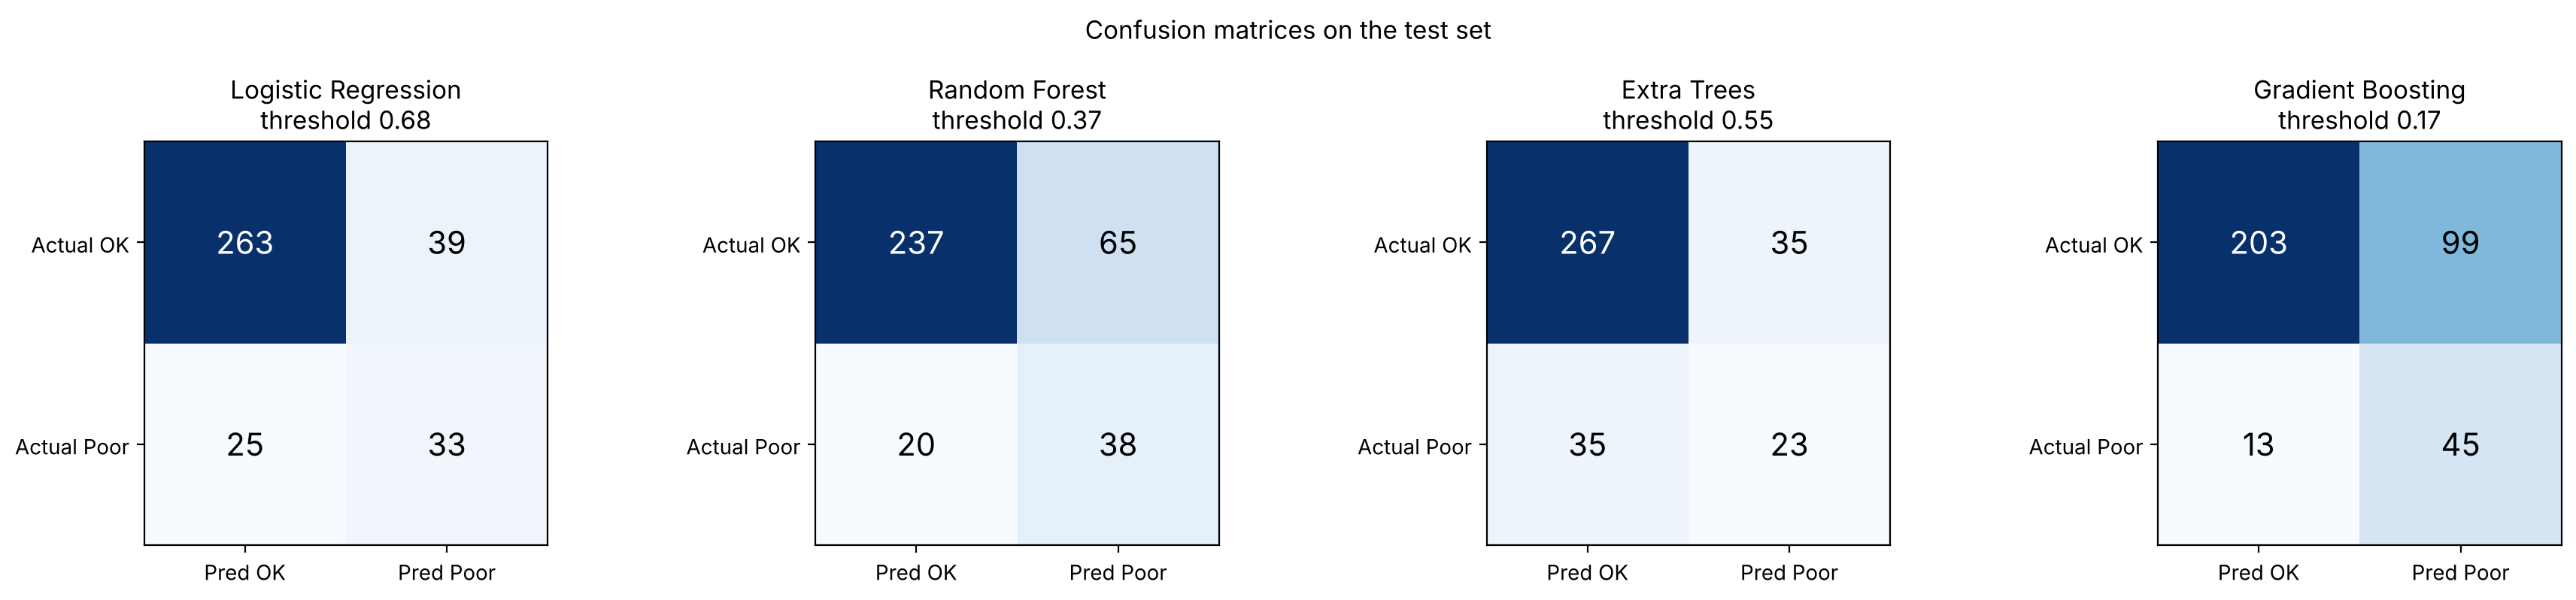

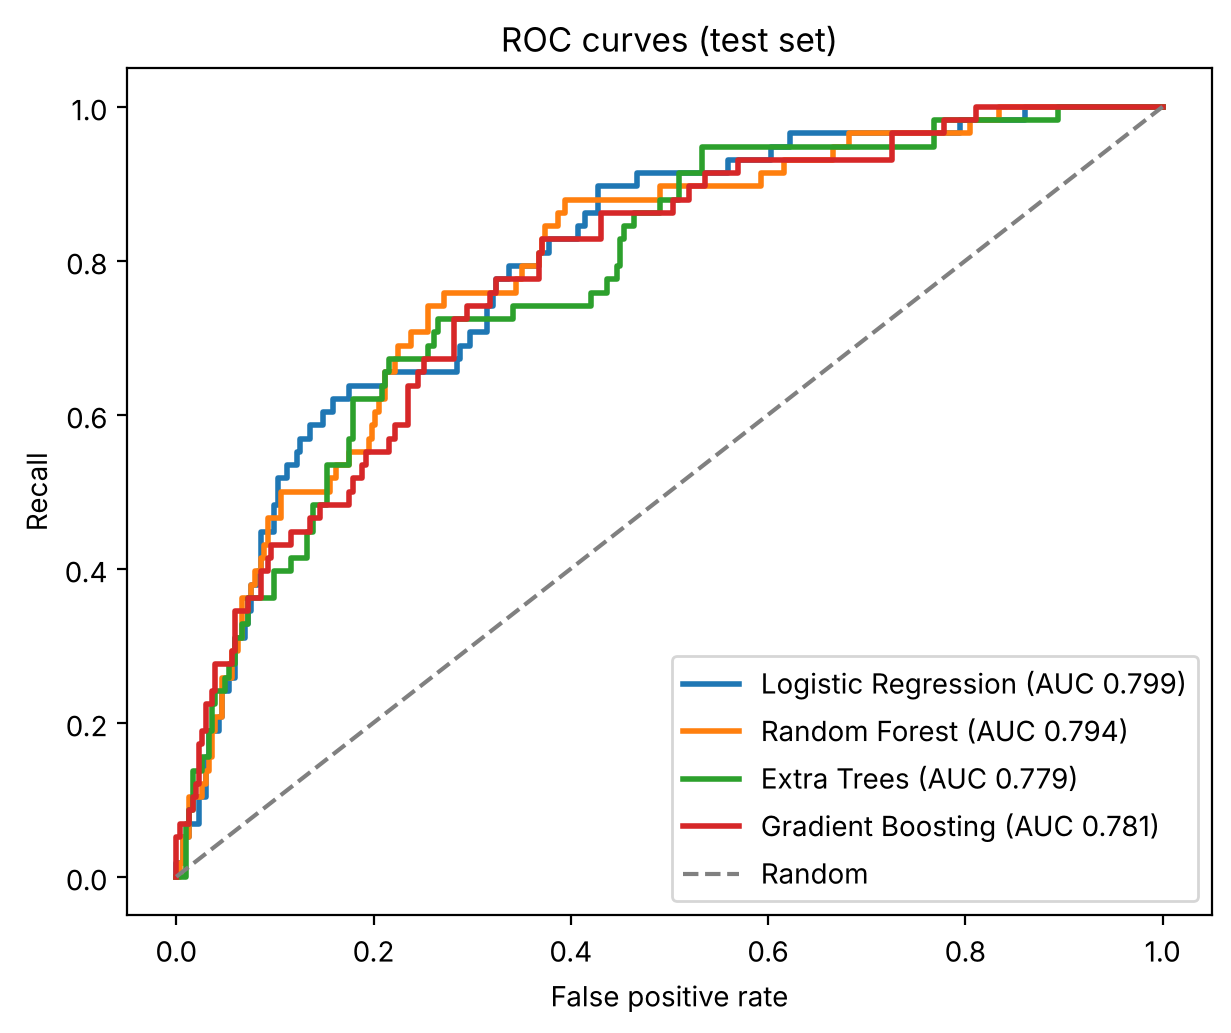

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, r) in zip(axes, results.iterrows()):
    cm = confusion_matrix(y_test, test_probs[name] >= r["Threshold"])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15, color="white" if cm[i, j] > 150 else "black")
    ax.set_xticks([0, 1], ["Pred OK", "Pred Poor"]); ax.set_yticks([0, 1], ["Actual OK", "Actual Poor"])
    ax.set_title(f"{name}\nthreshold {r['Threshold']:.2f}")
plt.suptitle("Confusion matrices on the test set"); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", c="grey", label="Random")
plt.xlabel("False positive rate"); plt.ylabel("Recall"); plt.title("ROC curves (test set)"); plt.legend(); plt.show()

### Final model and justification

In [27]:
best = results.sort_values(["CV PR-AUC", "CV ROC-AUC"], ascending=False).index[0]   # chosen on CV, not test
model, THRESHOLD = fitted[best], results.loc[best, "Threshold"]
b = results.loc[best]
print(f"Final model: {best}  (decision threshold {THRESHOLD:.2f})")
print(f"- Best cross-validated PR-AUC ({b['CV PR-AUC']:.3f}) and ROC-AUC ({b['CV ROC-AUC']:.3f}), chosen without touching the test set")
print(f"- Test: ROC-AUC {b['ROC-AUC']:.3f}, F1 {b['F1']:.3f}, recall {b['Recall']:.0%}, precision {b['Precision']:.0%} (random picking = {BASE:.0%})")
print("- Explainable: each feature pushes risk one clear way, so the coordinator can see why a group is flagged")
print("- Tree models did not beat it on CV; with ~1,400 rows extra complexity adds variance, not signal")

Final model: Logistic Regression  (decision threshold 0.68)
- Best cross-validated PR-AUC (0.455) and ROC-AUC (0.829), chosen without touching the test set
- Test: ROC-AUC 0.799, F1 0.508, recall 57%, precision 46% (random picking = 16%)
- Explainable: each feature pushes risk one clear way, so the coordinator can see why a group is flagged
- Tree models did not beat it on CV; with ~1,400 rows extra complexity adds variance, not signal


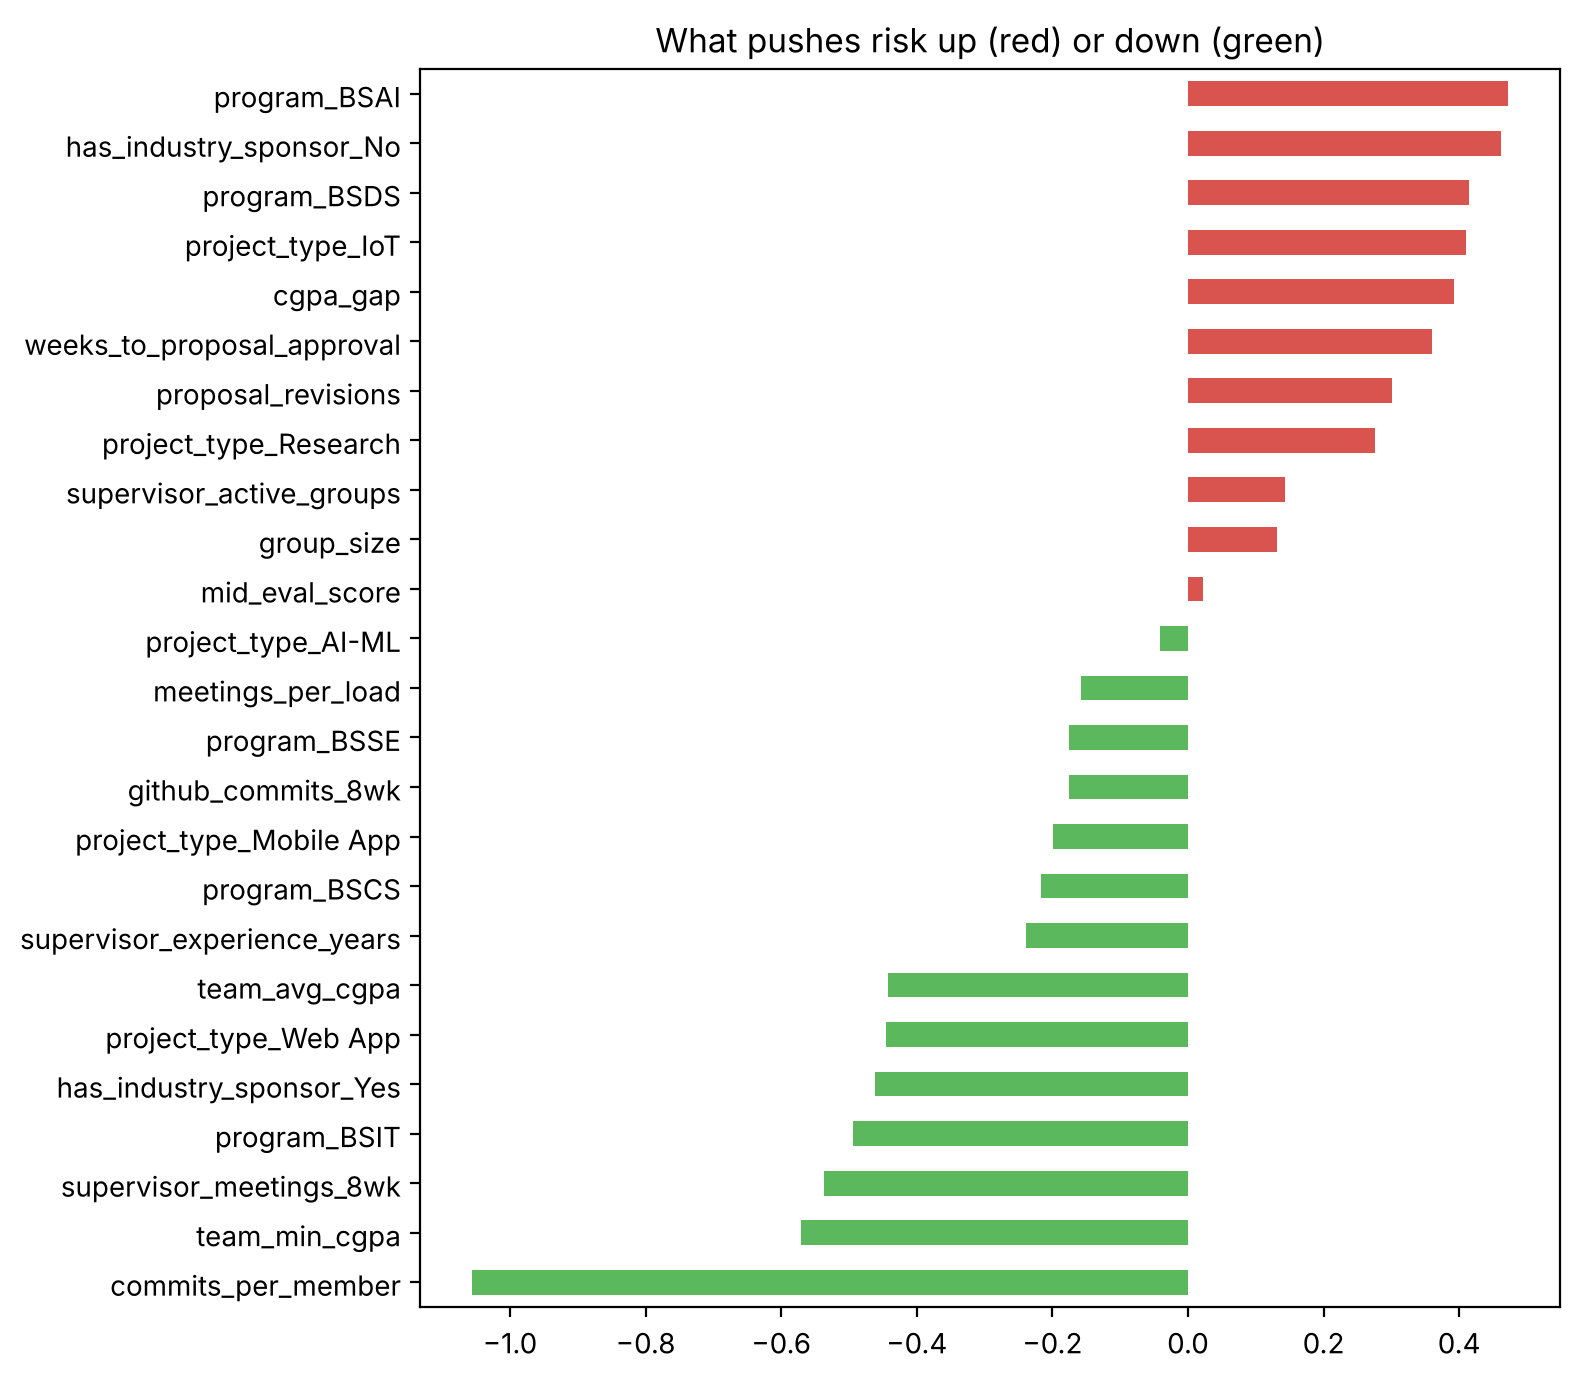

In [28]:
# what drives risk in the final model (standardised coefficients: + raises risk, - lowers it)
names = [n.split("__")[1] for n in model.named_steps["pre"].get_feature_names_out()]
coef = pd.Series(model.named_steps["clf"].coef_[0], index=names).sort_values()
coef.plot.barh(figsize=(8, 7), color=["#5cb85c" if v < 0 else "#d9534f" for v in coef])
plt.title("What pushes risk up (red) or down (green)"); plt.tight_layout(); plt.show()

---
## A4 · Prediction Form: risk tiers
### Choosing the probability cut-offs
- **High** starts at the model's decision threshold (chosen in A3 by maximising F1 on cross-validation).
- **Low** ends at the highest cut-off where, on cross-validation, **at most 5%** of Low groups ended badly. Low means "safe to leave alone".
- **Medium** sits in between: worth watching.

Cut-offs are set on the *training* folds and then checked on the unseen test split.

In [29]:
oof = oof_probs[best]
T_HIGH = THRESHOLD
T_LOW = 0.02
for c in np.round(np.arange(0.02, T_HIGH, 0.01), 2):
    mask = oof < c
    if mask.sum() >= 30 and y_train[mask].mean() <= 0.05:
        T_LOW = float(c)

def tier_of(p):
    return "High" if p >= T_HIGH else ("Medium" if p >= T_LOW else "Low")

test = df.loc[X_test.index].copy()
test["probability"] = model.predict_proba(X_test)[:, 1]
test["predicted_poor"] = (test["probability"] >= THRESHOLD).astype(int)
test["tier"] = test["probability"].map(tier_of)

tiers = (test.groupby("tier")["y"].agg(test_groups="size", poor_outcomes="sum", observed_poor_rate="mean")
         .reindex(["Low", "Medium", "High"]))
tiers.insert(0, "probability range", [f"< {T_LOW:.2f}", f"{T_LOW:.2f} - {T_HIGH:.2f}", f">= {T_HIGH:.2f}"])
r = tiers["observed_poor_rate"].values
print(f"Cut-offs: Low < {T_LOW:.2f} <= Medium < {T_HIGH:.2f} <= High")
print("Rate rises Low -> Medium -> High on the test split:", bool(r[0] < r[1] < r[2]))
tiers.style.format({"observed_poor_rate": "{:.1%}"})

Cut-offs: Low < 0.41 <= Medium < 0.68 <= High
Rate rises Low -> Medium -> High on the test split: True


,probability range,test_groups,poor_outcomes,observed_poor_rate
tier,,,,
Low,< 0.41,211,12,5.7%
Medium,0.41 - 0.68,77,13,16.9%
High,>= 0.68,72,33,45.8%


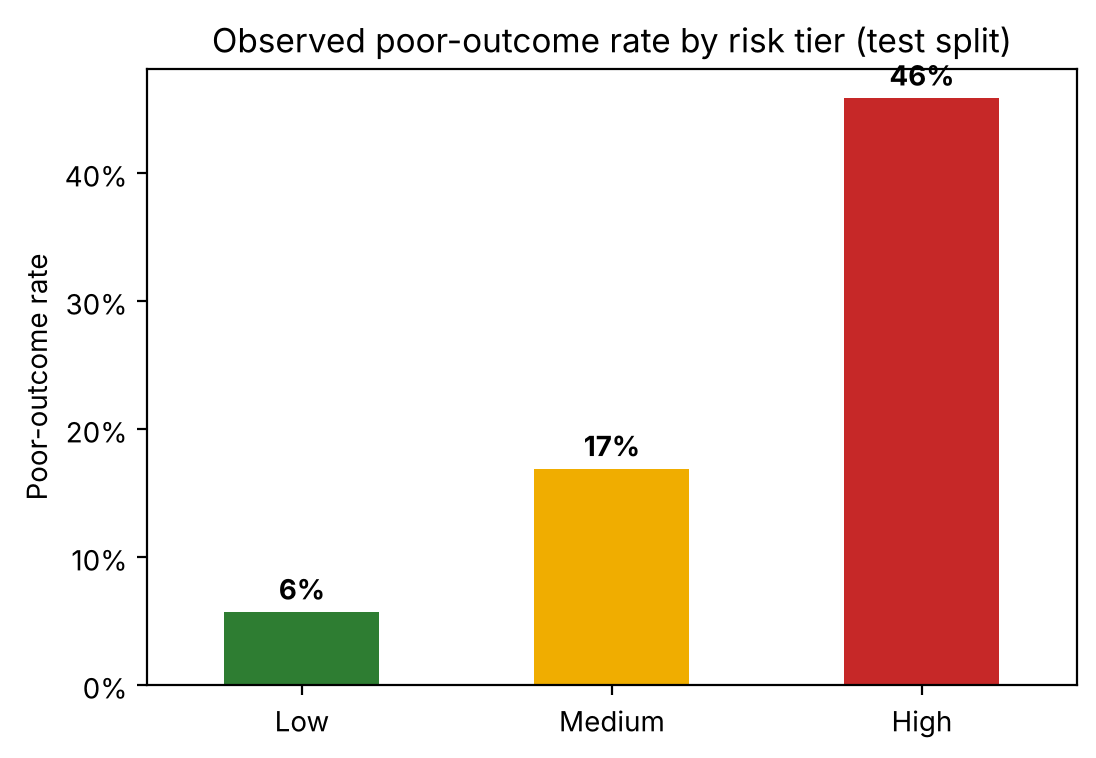

In [30]:
TIER_COLOR = {"Low": "#2e7d32", "Medium": "#f0ad00", "High": "#c62828"}
ax = tiers["observed_poor_rate"].plot.bar(color=[TIER_COLOR[t] for t in tiers.index], rot=0, figsize=(6, 4))
for i, v in enumerate(tiers["observed_poor_rate"]):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontweight="bold")
ax.yaxis.set_major_formatter(pct); ax.set(title="Observed poor-outcome rate by risk tier (test split)", xlabel="", ylabel="Poor-outcome rate")
plt.show()

---
## A5 · Prediction Explainability
**Method:** for each input, we replace the group's value with a *typical* value (the training median, or the most common category) and see how much the predicted risk changes.
- If risk **drops** when a value is made typical, that value was **pushing risk up**.
- The result is in percentage points of risk, which is easy to explain to a non-technical coordinator.

Each top risk driver is tied to one concrete support step.

In [31]:
INPUTS = ["group_size", "team_avg_cgpa", "team_min_cgpa", "program", "project_type", "has_industry_sponsor",
          "proposal_revisions", "weeks_to_proposal_approval", "supervisor_experience_years", "supervisor_active_groups",
          "supervisor_meetings_8wk", "github_commits_8wk", "mid_eval_score"]
LABEL = {"group_size": "group size", "team_avg_cgpa": "team average CGPA", "team_min_cgpa": "weakest member's CGPA",
         "program": "program", "project_type": "project type", "has_industry_sponsor": "industry sponsor",
         "proposal_revisions": "proposal revisions", "weeks_to_proposal_approval": "weeks to proposal approval",
         "supervisor_experience_years": "supervisor experience (yrs)", "supervisor_active_groups": "supervisor's active groups",
         "supervisor_meetings_8wk": "supervisor meetings in 8 weeks", "github_commits_8wk": "GitHub commits in 8 weeks",
         "mid_eval_score": "mid-evaluation score"}
train_df = df.loc[X_train.index]
TYPICAL = {f: (train_df[f].mode()[0] if f in CAT else float(train_df[f].median())) for f in INPUTS}

SUPPORT = {
    "supervisor_meetings_8wk": "Few supervisor meetings: book a fixed weekly 30-minute slot with the supervisor.",
    "github_commits_8wk": "Low coding activity: set weekly code milestones and a short Friday demo.",
    "mid_eval_score": "Weak mid-evaluation: hold a follow-up review within 2 weeks to fix the gaps the panel flagged.",
    "team_min_cgpa": "Weakest member struggling: pair them with a stronger teammate on one clearly owned module.",
    "team_avg_cgpa": "Academically weaker team: arrange a TA or lab-mentor check-in every two weeks.",
    "supervisor_active_groups": "Supervisor overloaded: add a co-supervisor or move the group to a lighter load.",
    "supervisor_experience_years": "New supervisor: pair them with an experienced co-supervisor.",
    "proposal_revisions": "Scope kept changing: run a scope-cutting session to lock a minimum viable version.",
    "weeks_to_proposal_approval": "Slow start: agree a catch-up plan with dated milestones for the next 4 weeks.",
    "group_size": "Team size is a risk: one named owner per module and a shared task board.",
    "project_type": "Higher-risk project type: fortnightly checkpoints with concrete deliverables.",
    "has_industry_sponsor": "No sponsor: connect the group with an industry or alumni mentor.",
    "program": "Program-level risk: invite the group to the department's FYP clinic sessions.",
}

def clean_input(row):
    row = dict(row)
    row["team_min_cgpa"] = min(row["team_min_cgpa"], row["team_avg_cgpa"])     # min can't exceed avg
    if row["group_size"] == 1:
        row["team_min_cgpa"] = row["team_avg_cgpa"]                              # solo: min == avg
    return row

def predict_proba_row(row):
    X1 = add_features(pd.DataFrame([clean_input(row)]))[NUM + CAT]
    return float(model.predict_proba(X1)[0, 1])

def explain(row):
    base = predict_proba_row(row)
    out = []
    for f in INPUTS:
        alt = dict(row); alt[f] = TYPICAL[f]
        if f == "team_avg_cgpa":   # move the whole team's CGPA, keep the gap between avg and weakest member
            alt["team_min_cgpa"] = max(0, TYPICAL[f] - (row["team_avg_cgpa"] - min(row["team_min_cgpa"], row["team_avg_cgpa"])))
        out.append({"feature": f, "factor": LABEL[f], "value": row[f], "typical": TYPICAL[f],
                    "impact_pts": (base - predict_proba_row(alt)) * 100})
    return base, pd.DataFrame(out).sort_values("impact_pts", ascending=False).reset_index(drop=True)

def fmt(f, v):
    if isinstance(v, str): return v
    return f"{v:.2f}" if "cgpa" in f else (f"{v:.1f}" if f == "mid_eval_score" else f"{v:.0f}")

def explanation_text(prob, tier, ex):
    up = ex[ex.impact_pts > 0.5].head(3)
    down = ex[ex.impact_pts < -0.5].sort_values("impact_pts").head(3)
    s = f"This group has a {prob:.0%} estimated chance of failing or carrying over ({tier} risk). "
    if len(up):
        s += "Risk is pushed up mainly by: " + "; ".join(
            f"{r.factor} of {fmt(r.feature, r.value)} (typical {fmt(r.feature, r.typical)})" for r in up.itertuples()) + ". "
    if len(down):
        s += "Working in its favour: " + "; ".join(f"{r.factor} of {fmt(r.feature, r.value)}" for r in down.itertuples()) + "."
    action = SUPPORT[up.iloc[0].feature] if len(up) else "No single factor stands out: keep the normal check-in schedule."
    return s, action, up, down

### The analyser: prediction + badge + explanation in one place
`analyse(row)` shows the predicted outcome, the exact probability, a colour-coded tier badge, the top 3 factors pushing risk up and down, a plain-English summary and a support step.

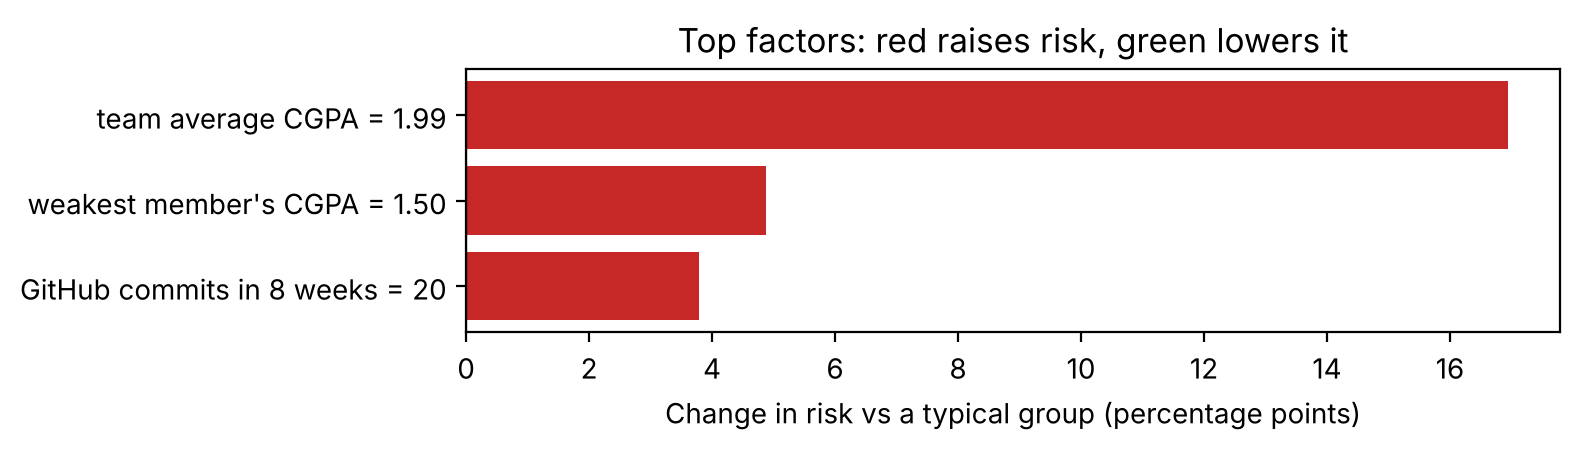

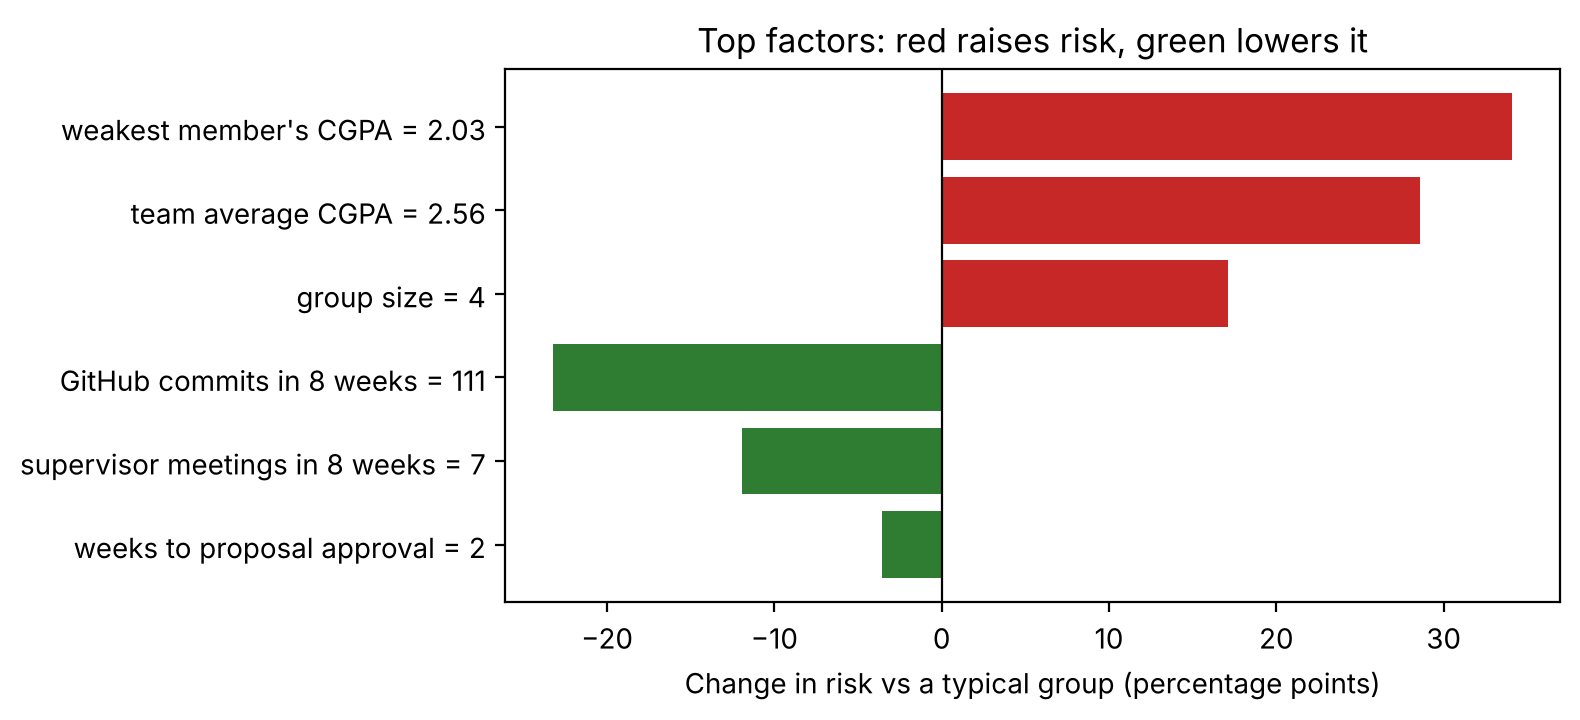

In [32]:
from IPython.display import display, HTML

def analyse(row, title="FYP group"):
    prob, ex = explain(row)
    tier = tier_of(prob)
    outcome = "POOR OUTCOME likely (fail / carry over)" if prob >= THRESHOLD else "Likely to PASS"
    text, action, up, down = explanation_text(prob, tier, ex)
    c = TIER_COLOR[tier]
    display(HTML(f'''
    <div style="border:1px solid #ddd;border-radius:10px;padding:14px 18px;font-family:sans-serif;max-width:900px">
      <div style="font-size:15px;color:#555">{title}</div>
      <div style="display:flex;gap:28px;align-items:center;margin:8px 0">
        <span style="background:{c};color:white;border-radius:999px;padding:6px 20px;font-size:20px;font-weight:700">● {tier} risk</span>
        <span style="font-size:26px;font-weight:700">{prob:.1%}</span><span style="color:#555">probability of poor outcome</span>
      </div>
      <div style="font-size:16px"><b>Predicted outcome:</b> {outcome} &nbsp;<span style="color:#888">(decision threshold {THRESHOLD:.2f})</span></div>
      <p style="font-size:15px;line-height:1.5">{text}</p>
      <div style="background:#f3f7ff;border-left:4px solid #3b6fd8;padding:8px 12px;font-size:15px"><b>Suggested support step:</b> {action}</div>
    </div>'''))
    top = pd.concat([up, down])
    if len(top):
        fig, ax = plt.subplots(figsize=(8, 0.45 * len(top) + 1))
        lab = [f"{r.factor} = {fmt(r.feature, r.value)}" for r in top.itertuples()]
        ax.barh(lab[::-1], top["impact_pts"][::-1], color=["#c62828" if v > 0 else "#2e7d32" for v in top["impact_pts"][::-1]])
        ax.axvline(0, c="black", lw=0.8)
        ax.set(xlabel="Change in risk vs a typical group (percentage points)", title="Top factors: red raises risk, green lowers it")
        plt.tight_layout(); plt.show()
    return prob, tier

# Example: the three groups the model ranks highest, middle and lowest in the test set
ranked = test.sort_values("probability", ascending=False)
for gid, label in [(ranked.iloc[0].group_id, "Highest-risk test group"),
                   (ranked[ranked.tier == "Medium"].iloc[len(ranked[ranked.tier == "Medium"]) // 2].group_id, "A Medium-risk test group"),
                   (ranked.iloc[-1].group_id, "Lowest-risk test group")]:
    r = test.loc[test.group_id == gid].iloc[0]
    analyse({f: r[f] for f in INPUTS}, f"{label}: {gid} (actual outcome: {r.poor_outcome})")

### Interactive form: enter the week-8 details of any group
Run the cell, fill in the fields and click **Analyse group**. (The widgets need a running kernel: in VS Code, click Run All first.)

In [33]:
import ipywidgets as w

style = {"description_width": "190px"}; lay = w.Layout(width="420px")
form = {
    "group_size": w.BoundedIntText(3, min=1, max=5, description="Group size", style=style, layout=lay),
    "team_avg_cgpa": w.BoundedFloatText(3.06, min=0, max=4, step=0.01, description="Team average CGPA", style=style, layout=lay),
    "team_min_cgpa": w.BoundedFloatText(2.75, min=0, max=4, step=0.01, description="Weakest member's CGPA", style=style, layout=lay),
    "program": w.Dropdown(options=["BSCS", "BSSE", "BSAI", "BSIT", "BSDS"], description="Program", style=style, layout=lay),
    "project_type": w.Dropdown(options=["Web App", "Mobile App", "AI-ML", "IoT", "Research"], description="Project type", style=style, layout=lay),
    "has_industry_sponsor": w.Dropdown(options=["No", "Yes"], description="Industry sponsor", style=style, layout=lay),
    "proposal_revisions": w.BoundedIntText(1, min=0, max=10, description="Proposal revisions", style=style, layout=lay),
    "weeks_to_proposal_approval": w.BoundedIntText(3, min=0, max=30, description="Weeks to proposal approval", style=style, layout=lay),
    "supervisor_experience_years": w.BoundedIntText(6, min=0, max=45, description="Supervisor experience (yrs)", style=style, layout=lay),
    "supervisor_active_groups": w.BoundedIntText(6, min=1, max=15, description="Supervisor's active groups", style=style, layout=lay),
    "supervisor_meetings_8wk": w.BoundedIntText(5, min=0, max=30, description="Supervisor meetings (8 wk)", style=style, layout=lay),
    "github_commits_8wk": w.BoundedIntText(57, min=0, max=1000, description="GitHub commits (8 wk)", style=style, layout=lay),
    "mid_eval_score": w.BoundedFloatText(72.0, min=0, max=100, step=0.1, description="Mid-evaluation score", style=style, layout=lay),
}
button = w.Button(description="Analyse group", button_style="primary", icon="search")
result = w.Output()

def on_click(_):
    with result:
        result.clear_output()
        row = {k: v.value for k, v in form.items()}
        if row["team_min_cgpa"] > row["team_avg_cgpa"]:
            print("Note: weakest member's CGPA cannot exceed the team average, so it was capped at the average.")
        analyse(row, "Entered group")

button.on_click(on_click)
fields = list(form.values())
display(w.VBox([w.HBox([w.VBox(fields[:7]), w.VBox(fields[7:])]), button, result]))

---
## A5 · Fairness Check
Gender and campus were **not** given to the model. Here we check whether its predictions still treat groups differently, using the test split.
- **Predicted poor-outcome rate:** how often the model flags groups in each category.
- **Recall:** of the groups that really ended badly, how many the model caught. A big recall gap would mean one group's struggling students get missed more often.
- 95% confidence intervals (Wilson) show how much the numbers could move given the small counts.

In [34]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

def fairness_table(col, min_groups=0):
    rows = []
    for g, d in test.groupby(col):
        if len(d) < min_groups: continue
        pos = d[d.y == 1]; caught = int(pos.predicted_poor.sum())
        lo, hi = wilson(caught, len(pos))
        rows.append({col: g, "test groups": len(d), "actual poor": len(pos),
                     "actual poor rate": d.y.mean(), "predicted poor rate": d.predicted_poor.mean(),
                     "recall": caught / len(pos) if len(pos) else np.nan, "recall 95% CI": f"{lo:.0%} - {hi:.0%}",
                     "_lo": lo, "_hi": hi})
    return pd.DataFrame(rows).set_index(col)

fmt_cols = {"actual poor rate": "{:.1%}", "predicted poor rate": "{:.1%}", "recall": "{:.1%}"}
gender = fairness_table("leader_gender")
gender.drop(columns=["_lo", "_hi"]).style.format(fmt_cols)

,test groups,actual poor,actual poor rate,predicted poor rate,recall,recall 95% CI
leader_gender,,,,,,
Female,150,21,14.0%,23.3%,61.9%,41% - 79%
Male,210,37,17.6%,17.6%,54.1%,38% - 69%


In [35]:
campus = fairness_table("campus", min_groups=30)
print("Campuses with at least 30 test groups:", len(campus), "of", test.campus.nunique())
campus.drop(columns=["_lo", "_hi"]).sort_values("recall").style.format(fmt_cols)

Campuses with at least 30 test groups: 8 of 8


,test groups,actual poor,actual poor rate,predicted poor rate,recall,recall 95% CI
campus,,,,,,
Lahore,64,10,15.6%,15.6%,40.0%,17% - 69%
Quetta,35,7,20.0%,14.3%,42.9%,16% - 75%
Faisalabad,31,6,19.4%,16.1%,50.0%,19% - 81%
Karachi,81,7,8.6%,18.5%,57.1%,25% - 84%
Peshawar,30,8,26.7%,36.7%,62.5%,31% - 86%
Islamabad,42,6,14.3%,16.7%,66.7%,30% - 90%
Rawalpindi,33,9,27.3%,24.2%,66.7%,35% - 88%
Multan,44,5,11.4%,25.0%,80.0%,38% - 96%


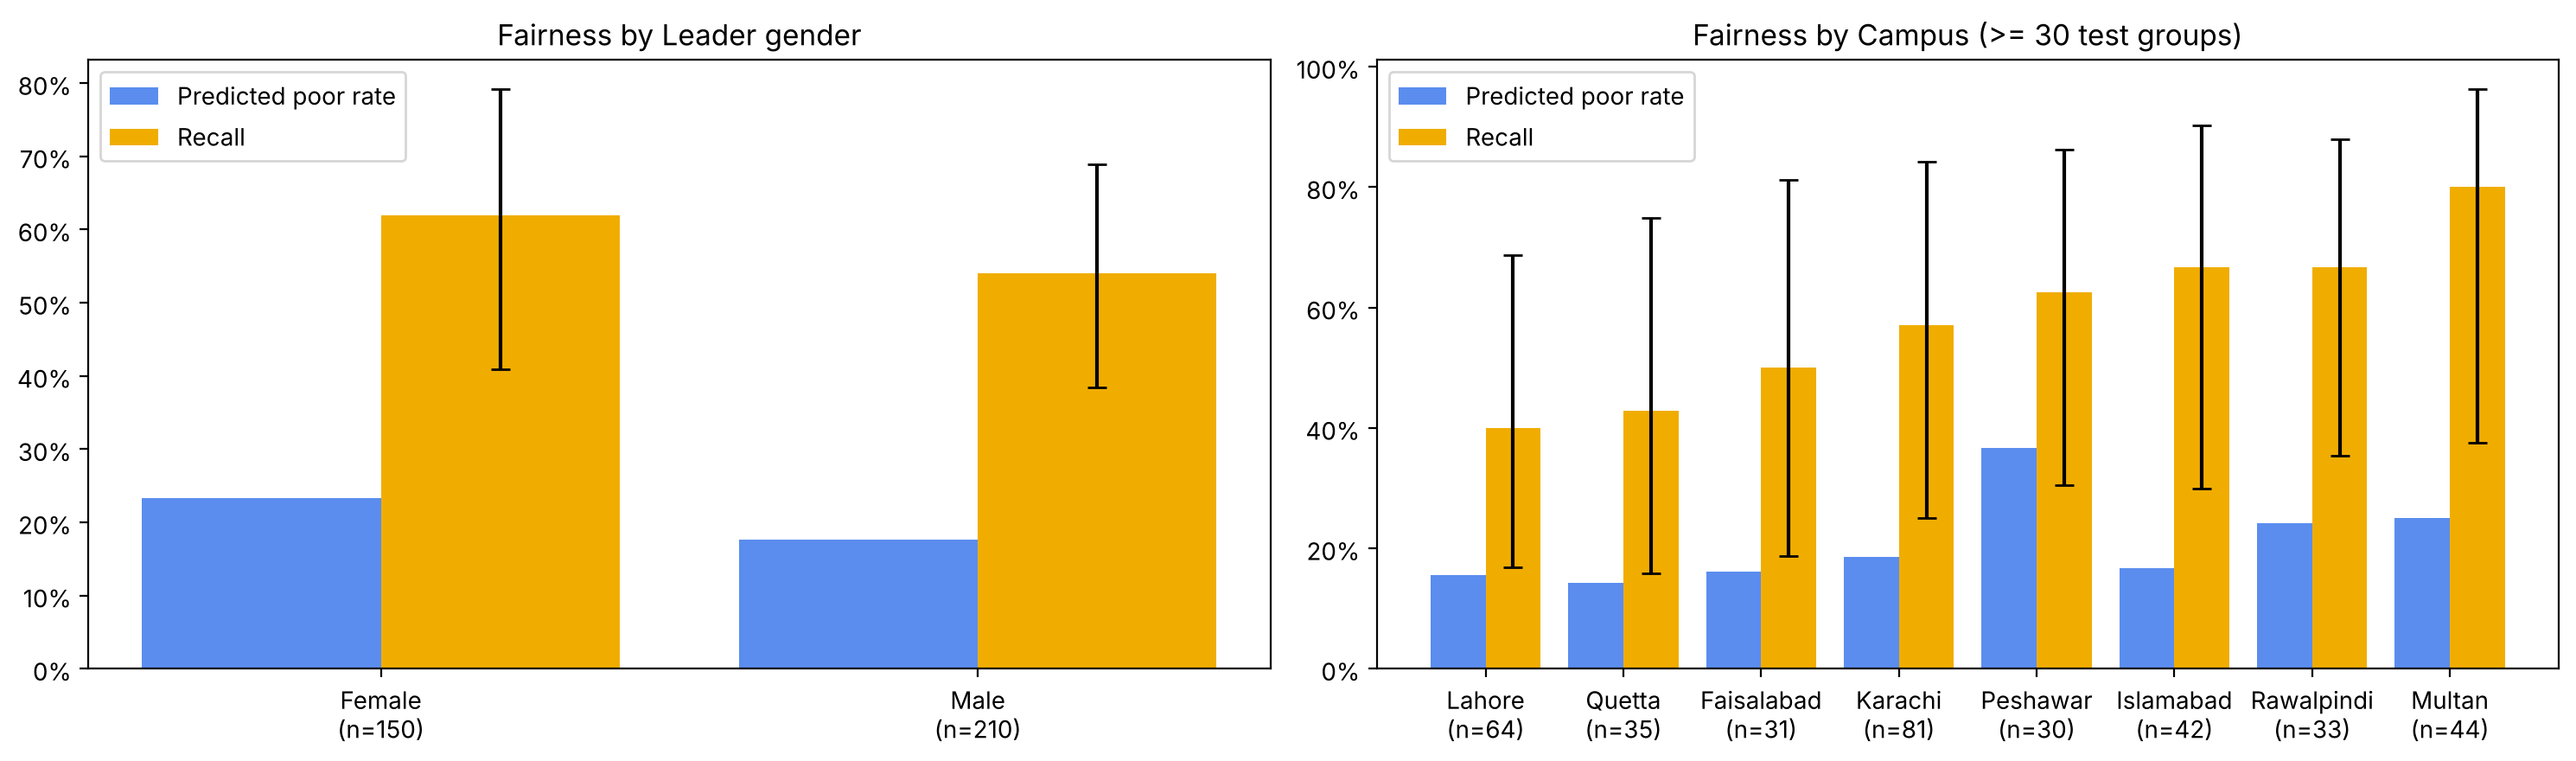

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (t, name) in zip(axes, [(gender, "Leader gender"), (campus.sort_values("recall"), "Campus (>= 30 test groups)")]):
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["predicted poor rate"], 0.4, label="Predicted poor rate", color="#5b8def")
    ax.bar(x + 0.2, t["recall"], 0.4, label="Recall", color="#f0ad00",
           yerr=[t["recall"] - t["_lo"], t["_hi"] - t["recall"]], capsize=4)
    ax.set_xticks(x, [f"{i}\n(n={n})" for i, n in zip(t.index, t["test groups"])])
    ax.yaxis.set_major_formatter(pct); ax.set_title(f"Fairness by {name}"); ax.legend()
plt.tight_layout(); plt.show()

In [37]:
def gap(t, col):
    return t[col].max() - t[col].min(), t[col].idxmax(), t[col].idxmin()

g_pred, g_rec = gap(gender, "predicted poor rate"), gap(gender, "recall")
c_pred, c_rec = gap(campus, "predicted poor rate"), gap(campus, "recall")
overlap_g = gender["_lo"].max() <= gender["_hi"].min()
overlap_c = campus["_lo"].max() <= campus["_hi"].min()

print(f"Gender : Male n={gender.loc['Male', 'test groups']}, Female n={gender.loc['Female', 'test groups']}")
print(f"         predicted-rate gap {g_pred[0]:.1%} ({g_pred[1]} higher), recall gap {g_rec[0]:.1%} ({g_rec[1]} higher)")
print(f"Campus : largest predicted-rate gap {c_pred[0]:.1%} ({c_pred[1]} vs {c_pred[2]})")
print(f"         largest recall gap {c_rec[0]:.1%} ({c_rec[1]} vs {c_rec[2]})")
print()
print("TAKEAWAY:")
print(f"Gender: {'no clear' if overlap_g else 'a'} disparity. The recall gap of {g_rec[0]:.0%} sits inside overlapping confidence intervals, "
      f"because each gender has only about {int(gender['actual poor'].mean())} actual poor outcomes in the test set." if overlap_g else
      f"Gender: the recall gap of {g_rec[0]:.0%} is larger than chance would explain and should be investigated.")
pr = gender["predicted poor rate"]; ar = gender["actual poor rate"]
print(f"Flag rate vs reality: Female-led groups are flagged {pr['Female']:.0%} of the time (actual {ar['Female']:.0%}), "
      f"Male-led {pr['Male']:.0%} (actual {ar['Male']:.0%}). "
      + ("The model slightly over-flags Female-led groups. With only 150 groups this is within noise, but worth watching. "
         "Over-flagging means extra support, not punishment." if pr['Female'] - ar['Female'] > pr['Male'] - ar['Male'] + 0.02 else
         "Flag rates track the actual rates closely."))
print(f"Campus: the {c_rec[0]:.0%} recall gap between {c_rec[1]} and {c_rec[2]} looks large but rests on only "
      f"{int(campus.loc[c_rec[1], 'actual poor'])} and {int(campus.loc[c_rec[2], 'actual poor'])} poor outcomes, so the intervals "
      f"{'overlap and we cannot call it a real disparity' if overlap_c else 'do not fully overlap. Worth monitoring'}. "
      "Confidence is low: we would re-check this with next year's groups before acting on it.")

Gender : Male n=210, Female n=150
         predicted-rate gap 5.7% (Female higher), recall gap 7.9% (Female higher)
Campus : largest predicted-rate gap 22.4% (Peshawar vs Quetta)
         largest recall gap 40.0% (Multan vs Lahore)

TAKEAWAY:
Gender: no clear disparity. The recall gap of 8% sits inside overlapping confidence intervals, because each gender has only about 29 actual poor outcomes in the test set.
Flag rate vs reality: Female-led groups are flagged 23% of the time (actual 14%), Male-led 18% (actual 18%). The model slightly over-flags Female-led groups. With only 150 groups this is within noise, but worth watching. Over-flagging means extra support, not punishment.
Campus: the 40% recall gap between Multan and Lahore looks large but rests on only 5 and 10 poor outcomes, so the intervals overlap and we cannot call it a real disparity. Confidence is low: we would re-check this with next year's groups before acting on it.
